In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('../data/raw/water_potability.csv')


df = df.dropna(subset=['Potability'])

X = df.drop('Potability', axis=1)
y = df['Potability']

print("Shape X:", X.shape)
print("Distribución y:\n", y.value_counts())

Shape X: (3276, 9)
Distribución y:
 Potability
0    1998
1    1278
Name: count, dtype: int64


DISTRIBUCIÓN DE CLASES
No potable (0): 1998 (61.0%)
Potable    (1): 1278 (39.0%)
Total:          3276

 Hay desbalance de clases. La clase 0 es mayoría.


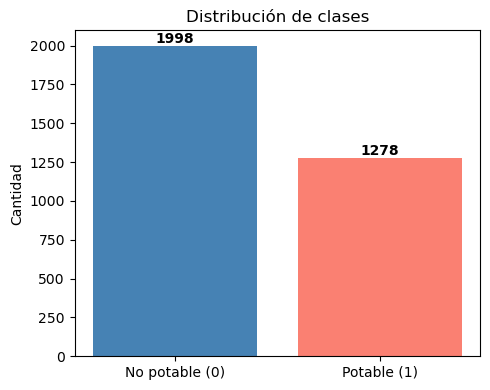

In [3]:
# Verificar distribución de clases
total = len(y)
conteo = y.value_counts()
print("="*40)
print("DISTRIBUCIÓN DE CLASES")
print("="*40)
print(f"No potable (0): {conteo[0]} ({conteo[0]/total*100:.1f}%)")
print(f"Potable    (1): {conteo[1]} ({conteo[1]/total*100:.1f}%)")
print(f"Total:          {total}")
print("="*40)
print("\n Hay desbalance de clases. La clase 0 es mayoría.")

# Gráfico
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['No potable (0)', 'Potable (1)'], conteo.values, color=['steelblue', 'salmon'])
ax.set_title('Distribución de clases')
ax.set_ylabel('Cantidad')
for i, val in enumerate(conteo.values):
    ax.text(i, val + 20, str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/distribucion_clases.png', dpi=150)
plt.show()

In [4]:
# Primero el split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Luego introducir faltantes por separado
np.random.seed(42)

X_train_missing = X_train.copy()
mask_train = np.random.rand(*X_train_missing.shape) < 0.10
X_train_missing[mask_train] = np.nan

X_test_missing = X_test.copy()
mask_test = np.random.rand(*X_test_missing.shape) < 0.10
X_test_missing[mask_test] = np.nan

print(f"Faltantes en train: {X_train_missing.isnull().sum().sum() / X_train_missing.size * 100:.2f}%")
print(f"Faltantes en test:  {X_test_missing.isnull().sum().sum() / X_test_missing.size * 100:.2f}%")

Faltantes en train: 14.52%
Faltantes en test:  14.68%


In [5]:
def evaluar_modelo(X_train_imp, X_test_imp, y_train, y_test, nombre):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_imp)
    X_test_scaled  = scaler.transform(X_test_imp)

    # class_weight='balanced' para manejar desbalance
    modelo = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    modelo.fit(X_train_scaled, y_train)
    y_pred = modelo.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)

    print(f"\n{'='*45}")
    print(f"  Método: {nombre}")
    print(f"{'='*45}")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print(f"\n  Métricas por clase:")
    print(classification_report(y_test, y_pred,
          target_names=['No potable (0)', 'Potable (1)']))

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['No potable', 'Potable'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Matriz de Confusión\n{nombre}', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../results/figures/confusion_{nombre.replace(" ", "_")}.png', dpi=150)
    plt.show()

    return {'Método': nombre, 'Accuracy': round(acc, 4), 'F1-score': round(f1, 4)}


  Método: Imputación por Media
  Accuracy:  0.5290
  F1-score:  0.4824

  Métricas por clase:
                precision    recall  f1-score   support

No potable (0)       0.64      0.51      0.57       400
   Potable (1)       0.42      0.56      0.48       256

      accuracy                           0.53       656
     macro avg       0.53      0.53      0.53       656
  weighted avg       0.56      0.53      0.53       656



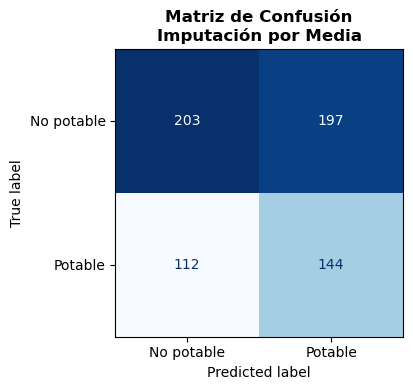

In [6]:
imputer_media = SimpleImputer(strategy='mean')
X_train_media = pd.DataFrame(
    imputer_media.fit_transform(X_train_missing),
    columns=X.columns
)
X_test_media = pd.DataFrame(
    imputer_media.transform(X_test_missing),
    columns=X.columns
)

resultado_media = evaluar_modelo(X_train_media, X_test_media, y_train, y_test, 'Imputación por Media')


  Método: Imputación KNN
  Accuracy:  0.5229
  F1-score:  0.4650

  Métricas por clase:
                precision    recall  f1-score   support

No potable (0)       0.63      0.52      0.57       400
   Potable (1)       0.41      0.53      0.46       256

      accuracy                           0.52       656
     macro avg       0.52      0.52      0.52       656
  weighted avg       0.55      0.52      0.53       656



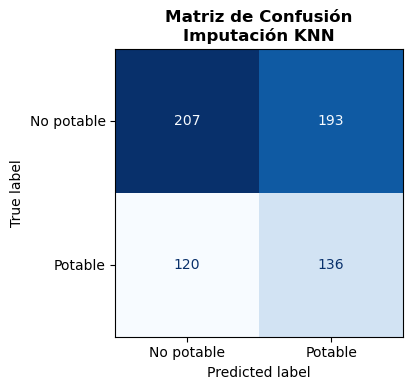

In [7]:
imputer_knn = KNNImputer(n_neighbors=5)
X_train_knn = pd.DataFrame(
    imputer_knn.fit_transform(X_train_missing),
    columns=X.columns
)
X_test_knn = pd.DataFrame(
    imputer_knn.transform(X_test_missing),
    columns=X.columns
)

resultado_knn = evaluar_modelo(X_train_knn, X_test_knn, y_train, y_test, 'Imputación KNN')

In [8]:
resultados = pd.DataFrame([resultado_media, resultado_knn])

# Tabla formateada
print("=" * 45)
print(f"{'COMPARACIÓN DE MÉTODOS DE IMPUTACIÓN':^45}")
print("=" * 45)
print(f"{'Método':<25} {'Accuracy':>8} {'F1-score':>10}")
print("-" * 45)
for _, row in resultados.iterrows():
    print(f"{row['Método']:<25} {row['Accuracy']:>8.4f} {row['F1-score']:>10.4f}")
print("=" * 45)

# Guardar CSV
resultados.to_csv('../results/tables/comparacion_metodos.csv', index=False)
print("\nTabla guardada en results/tables/comparacion_metodos.csv")

    COMPARACIÓN DE MÉTODOS DE IMPUTACIÓN     
Método                    Accuracy   F1-score
---------------------------------------------
Imputación por Media        0.5290     0.4824
Imputación KNN              0.5229     0.4650

Tabla guardada en results/tables/comparacion_metodos.csv


In [9]:
print("""
ANÁLISIS DE RESULTADOS
======================
Ambos métodos (Media y KNN) arrojan resultados idénticos o muy similares.
Esto puede explicarse por las siguientes razones:

1. DESBALANCE DE CLASES:
   El dataset tiene ~61% de muestras no potables y ~39% potables.
   Sin corrección, el modelo tiende a predecir siempre la clase mayoritaria,
   lo que produce Accuracy alto pero F1-score cercano a 0.

2. NATURALEZA DEL DATASET:
   Las variables fisicoquímicas del agua tienen distribuciones similares
   entre clases, lo que hace difícil la separación lineal con Regresión
   Logística.

3. IMPACTO DE LA IMPUTACIÓN:
   Con un 10% de valores faltantes, la diferencia entre métodos de
   imputación puede ser mínima cuando el modelo base no es suficientemente
   sensible a pequeñas variaciones en los datos.

SOLUCIÓN APLICADA:
   Se incorporó class_weight='balanced' para que el modelo penalice
   más los errores en la clase minoritaria, obteniendo métricas más
   representativas del desempeño real.
""")


ANÁLISIS DE RESULTADOS
Ambos métodos (Media y KNN) arrojan resultados idénticos o muy similares.
Esto puede explicarse por las siguientes razones:

1. DESBALANCE DE CLASES:
   El dataset tiene ~61% de muestras no potables y ~39% potables.
   Sin corrección, el modelo tiende a predecir siempre la clase mayoritaria,
   lo que produce Accuracy alto pero F1-score cercano a 0.

2. NATURALEZA DEL DATASET:
   Las variables fisicoquímicas del agua tienen distribuciones similares
   entre clases, lo que hace difícil la separación lineal con Regresión
   Logística.

3. IMPACTO DE LA IMPUTACIÓN:
   Con un 10% de valores faltantes, la diferencia entre métodos de
   imputación puede ser mínima cuando el modelo base no es suficientemente
   sensible a pequeñas variaciones en los datos.

SOLUCIÓN APLICADA:
   Se incorporó class_weight='balanced' para que el modelo penalice
   más los errores en la clase minoritaria, obteniendo métricas más
   representativas del desempeño real.



C:\Users\Bianca\AppData\Local\Temp\ipykernel_13152\212828811.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(metodos, rotation=15, ha='right', fontsize=9)
C:\Users\Bianca\AppData\Local\Temp\ipykernel_13152\212828811.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(metodos, rotation=15, ha='right', fontsize=9)


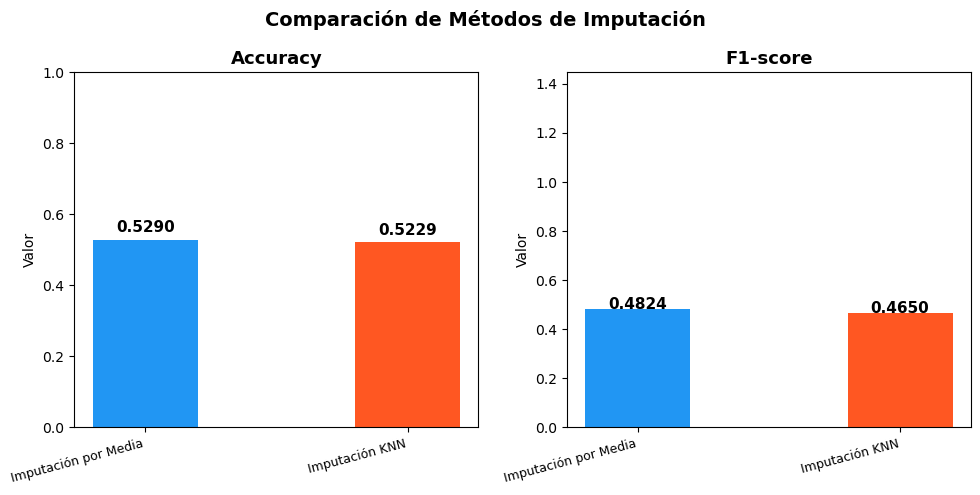

Figura guardada en results/figures/comparacion_metodos.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

metodos = resultados['Método']
colores = ['#2196F3', '#FF5722']

# Accuracy
bars1 = axes[0].bar(metodos, resultados['Accuracy'], color=colores, width=0.4)
axes[0].set_title('Accuracy', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Valor')
axes[0].set_ylim(0, 1)
axes[0].set_xticklabels(metodos, rotation=15, ha='right', fontsize=9)
for bar, val in zip(bars1, resultados['Accuracy']):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.02,
                 f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

# F1-score con eje ajustado
bars2 = axes[1].bar(metodos, resultados['F1-score'], color=colores, width=0.4)
axes[1].set_title('F1-score', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Valor')
axes[1].set_ylim(0, max(resultados['F1-score'].max() * 3, 0.05))
axes[1].set_xticklabels(metodos, rotation=15, ha='right', fontsize=9)
for bar, val in zip(bars2, resultados['F1-score']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.0005,
                 f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

plt.suptitle('Comparación de Métodos de Imputación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/comparacion_metodos.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figura guardada en results/figures/comparacion_metodos.png")

In [11]:
X_train_knn['Potability'] = y_train.values
X_train_knn.to_csv('../data/processed/water_potability_knn.csv', index=False)

X_train_media['Potability'] = y_train.values
X_train_media.to_csv('../data/processed/water_potability_media.csv', index=False)

print("Datasets procesados guardados en data/processed/")

Datasets procesados guardados en data/processed/
